# ICS 3202 Artificial Intelligence: Semester Project
# Base model: a Naive Bayes transaction categoriser

This notebook builds the base model for Akiba, a personal-finance app for students. The model reads an
M-Pesa transaction (a short description and an amount) and suggests one of nine expense categories.
Every number and figure below is computed when the notebook runs.

---
# From Deliverable 1 to Deliverable 2

Deliverable 1 (`Expenses_Exploration.ipynb`) explored `Expenses_clean.csv`, the Kaggle *Financial
Transactions Dataset (Expenses & Income)*: 938 rows of personal spending in BYN, with six columns
(`date_time`, `category`, `account`, `amount`, `currency`, `tags`).

That exploration showed the dataset has no description or merchant text column. Akiba's categoriser has
to map an M-Pesa description to a category, and rows that only carry a date, an account, an amount and an
already-filled category give the model nothing to learn from. Finding out that a dataset cannot support
the task is a valid result of exploration, not a failure. It is exactly the question exploration is for.

There is a second, separate reason. The expenses file has 14 categories (Cafe, Clothes, Fines, Leisure,
Loan given, Public transport and others) while Akiba has 9, so even with a text column the labels would
not line up without a mapping that drops or merges categories. `Income_clean.csv` (349 rows,
7 categories) is committed next to it in `data/`. Income is not classified in v1 of the categoriser.

With no real labelled data (the app has no users yet), the project builds its own training set from a
hand-made list of Kenyan merchants:

```
lexicon.json  →  generate.py  →  data/train.csv
```

`data/train.csv` is the dataset modelled in this notebook. The Kaggle data plays no part in training the
shipped model. It is still useful for tasks that need no description text, such as clustering spending
behaviour or forecasting monthly spend per category, which are candidates for a later deliverable.

---
# How this notebook follows CRISP-DM

The course frames data-mining projects with CRISP-DM, which has six phases. This notebook keeps its own
part structure, and each part names the phase it belongs to.

| CRISP-DM phase | Where it happens |
|---|---|
| Business understanding | Part A: what the app must produce, and the task type |
| Data understanding | The first sections of Part B, plus Part C (EDA) |
| Data preparation | Part B: the seven cleaning steps |
| Modelling | Part D: the base model |
| Evaluation | Part D's checks and the Part E model comparison |
| Deployment | The export to `out/model.json`, which the app's TypeScript server loads |

The notes call business understanding the most critical task, and data preparation is usually the
longest phase. That holds here too: Part B is the longest part of the notebook.

---
# Part A: The ML approach
*CRISP-DM phase: business understanding*

## What the app has to produce

A statement line such as `"merchant payment to naivas westlands"`, KES 1,240, must be turned into one of
nine categories plus a confidence score that decides whether to apply the label or ask the user. The
model must ship as a single JSON file that runs in pure TypeScript inside the app's Express server.

## The two datasets

| | Deliverable 1 dataset | Modelling dataset (this notebook) |
|---|---|---|
| File | `Expenses_clean.csv` (Kaggle) | `data/train.csv` |
| Origin | Exported from a finance-tracking app | Generated by `generate.py` from `lexicon.json` |
| Rows | 938 | 5,587 |
| Columns | `date_time`, `category`, `account`, `amount`, `currency`, `tags` | `description`, `amount`, `category`, `keyword` |
| Currency | BYN (Belarusian rouble) | KES |
| Has a text description? | No | Yes |

Only the second can train this model (see the bridge section).

## Task type and candidate algorithms

Every training row has its category, so this is **supervised learning**; the target is one of nine
labels, so it is **multi-class classification**. Clustering is ruled out because the labels already
exist, and regression because the target is not a number.

The six algorithms compared all come from the course's ML cheat sheet and the Theories of Machine
Learning lecture:

| Algorithm | Fit for this problem |
|---|---|
| **Multinomial Naive Bayes** | Built for word counts and fast to train. The model is a table of log-probabilities, so predicting takes a few lines of TypeScript. Chosen as the base model. |
| Logistic Regression | Strong linear text classifier, with regularisation built in |
| Decision Tree | Easy to read, but prone to over-fitting sparse features |
| K-Nearest Neighbours | Labels a row by its most similar training rows |
| Random Forest | Averages many trees to reduce over-fitting |
| Gradient Boosting | Builds trees in sequence, each correcting the last |

Transformer language models are ruled out: they are hundreds of megabytes and cannot run inside the
TypeScript server.

---
# Part B: Cleaning the data
*CRISP-DM phases: data understanding, then data preparation*

This part looks at where the data comes from, then works through the seven data cleaning steps from the
course notes in order, saying for each what was done or why it did not apply. The first cell loads the
libraries and finds `data/train.csv`.

In [1]:
import json, re, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

warnings.filterwarnings("ignore")
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linestyle": "-",
    "figure.facecolor": "white", "axes.facecolor": "white",
})

NAVY, BLUE, TEAL, RED, GREY = "#1C3F63", "#2A6FA8", "#127A73", "#C0564B", "#637586"
HEAT = LinearSegmentedColormap.from_list("heat", ["#FFFFFF", "#CFE0EE", "#2A6FA8", "#1C3F63"])

# Locate data/train.csv whether the notebook runs from notebooks/, the repo root, or Colab
CANDIDATES = [Path("data/train.csv"), Path("../data/train.csv"), Path("train.csv")]
TRAIN_CSV = next((p for p in CANDIDATES if p.exists()), None)
if TRAIN_CSV is None:
    raise FileNotFoundError(
        "data/train.csv not found. Run `python scripts/generate.py` at the repo root first, "
        "or upload data/train.csv if running in Colab."
    )
# Paths are reported relative to the repo root so no machine-specific directory ends up in the output
REPO_ROOT = TRAIN_CSV.resolve().parents[1] if TRAIN_CSV.parent.name == "data" else TRAIN_CSV.resolve().parent
print("Loaded from:", TRAIN_CSV.resolve().relative_to(REPO_ROOT).as_posix())

Loaded from: data/train.csv


## Where the data comes from

With no users yet, there is no labelled history. `generate.py` builds the training set from
`lexicon.json`, a hand-made list of 457 Kenyan merchants and keywords. Each keyword gets 11 to 14 rows,
each an M-Pesa-style sentence such as `pay bill to {keyword}`, with an amount drawn from a range set for
its category. The same twelve templates are used for every category, so only the keyword should carry
category information (checked in Step 2).

The generator already enforces some cleaning: it stops if a category has no keywords or no amount range,
rejects a keyword listed under two categories, and uses a fixed seed (42) so the file can be rebuilt
exactly.

In [2]:
raw = pd.read_csv(TRAIN_CSV)

print(f"Shape: {raw.shape[0]:,} rows x {raw.shape[1]} columns\n")
print("Datatypes:"); print(raw.dtypes.to_string())
# `keyword` records which lexicon entry produced the row; it is not used as a feature
raw.head(8)

Shape: 5,587 rows x 4 columns

Datatypes:
description      str
amount         int64
category         str
keyword          str


,description,amount,category,keyword
0,faiba cbd,340,Airtime & Data,faiba
1,buy goods grocery,115,Food,grocery
2,customer transfer to pharmacy,2612,Health,pharmacy
3,merchant payment to cash thika road,65,Other,cash
4,pay bill online to pizza,171,Food,pizza
5,pay bill online to faras,611,Transport,faras
6,gym branch westlands,2110,Personal Care,gym
7,customer transfer to m shwari,59,Other,m shwari


## Step 1: Scrub for duplicates

There are no exact duplicates (same description, amount and category). The 202 repeated descriptions
never disagree on the category, so they are consistent repeats rather than label noise, and they are
kept: dropping them would change the class balance.

The bigger issue is near-duplicates: each of the 457 keywords produces 11 to 14 rows that differ only in
template and amount. They are how the model learns each merchant, so they stay, but they affect
evaluation (see the limitation note in Part D).

In [3]:
# An exact duplicate has the same description, amount and category
exact_dupes = int(raw.duplicated(["description", "amount", "category"]).sum())
repeated_text = int(raw.description.duplicated().sum())
# A repeated description with two different categories would be contradictory label noise
contradictory = int((raw.groupby("description").category.nunique() > 1).sum())

print(f"Exact duplicate rows:                     {exact_dupes}")
print(f"Repeated description strings:             {repeated_text}")
print(f"Repeated descriptions with two categories: {contradictory}\n")

kw_stats = (raw.groupby("category")
              .agg(rows=("category", "size"), keywords=("keyword", "nunique"))
              .assign(rows_per_keyword=lambda t: (t.rows / t.keywords).round(1))
              .sort_values("keywords"))
display(kw_stats)
print(f"{raw.keyword.nunique()} distinct merchant keywords behind {len(raw):,} rows")

Exact duplicate rows:                     0
Repeated description strings:             202
Repeated descriptions with two categories: 0



,rows,keywords,rows_per_keyword
category,,,
Airtime & Data,602,43,14.0
Rent,630,45,14.0
Health,611,47,13.0
Personal Care,637,49,13.0
Other,612,51,12.0
Entertainment,636,53,12.0
Food,616,56,11.0
Academic,616,56,11.0
Transport,627,57,11.0


457 distinct merchant keywords behind 5,587 rows


## Step 2: Scrub for irrelevant data

Real descriptions contain receipt codes, phone numbers, digits and punctuation, which say nothing about
the category and are unique to each transaction. `clean()` in `scripts/features.py` replaces every
character that is not a letter or space with a space, then collapses repeated spaces. The app's
TypeScript code runs the same steps, so the notebook imports `features.py` rather than copying it. The
demo runs it on five made-up descriptions.

In [4]:
# Mirrors features.py exactly. Imported if available so the notebook cannot drift from the shipped code.
import sys
sys.path.insert(0, str(REPO_ROOT / "scripts"))   # scripts/ sits beside data/, from notebooks/ or the repo root
try:
    import features
    from features import clean, amount_bucket, to_document, vectorizer_kwargs
    print(f"Using {Path(features.__file__).resolve().relative_to(REPO_ROOT).as_posix()} "
          "from the repository (single source of truth).")
except ImportError:
    print("features.py not importable, so using the inline equivalent.")
    AMOUNT_BUCKETS = [(0,100,"amt_xs"), (100,500,"amt_s"), (500,2000,"amt_m"),
                      (2000,10000,"amt_l"), (10000,None,"amt_xl")]
    _NON_ALPHA, _SPACES = re.compile(r"[^a-z\s]+"), re.compile(r"\s+")

    def clean(text):
        text = "" if text is None else str(text)
        return _SPACES.sub(" ", _NON_ALPHA.sub(" ", text.lower())).strip()

    def amount_bucket(amount):
        v = abs(float(amount or 0))
        for low, high, tok in AMOUNT_BUCKETS:
            if high is None or v < high:
                return tok
        return AMOUNT_BUCKETS[-1][2]

    def to_document(description, amount):
        c = clean(description)
        b = amount_bucket(amount)
        return f"{c} {b}" if c else b

    def vectorizer_kwargs():
        return {"lowercase": False, "token_pattern": r"\S+", "ngram_range": (1, 2)}

demo = pd.DataFrame({
    "raw_description": ["Pay Bill to NAIVAS #4471", "ARTCAFFE LTD, Westlands",
                        "merchant payment to JAVA HOUSE", "UBER*TRIP 0712345678", "KPLC PREPAID TOKEN"],
    "amount": [1240, 85, 650, 320, 15000],
})
demo["after_clean()"]  = demo.raw_description.map(clean)
demo["amount_bucket()"] = demo.amount.map(amount_bucket)
demo["final_document"] = [to_document(d, a) for d, a in zip(demo.raw_description, demo.amount)]
display(demo)

print("The receipt code '#4471', the phone number and the '*' are all removed,")
print("and the amount comes back as a single token at the end (Step 7).")

Using scripts/features.py from the repository (single source of truth).


,raw_description,amount,after_clean(),amount_bucket(),final_document
0,Pay Bill to NAIVAS #4471,1240,pay bill to naivas,amt_m,pay bill to naivas amt_m
1,"ARTCAFFE LTD, Westlands",85,artcaffe ltd westlands,amt_xs,artcaffe ltd westlands amt_xs
2,merchant payment to JAVA HOUSE,650,merchant payment to java house,amt_m,merchant payment to java house amt_m
3,UBER*TRIP 0712345678,320,uber trip,amt_s,uber trip amt_s
4,KPLC PREPAID TOKEN,15000,kplc prepaid token,amt_xl,kplc prepaid token amt_xl


The receipt code '#4471', the phone number and the '*' are all removed,
and the amount comes back as a single token at the end (Step 7).


Template words ("pay", "bill", "lipa na mpesa") are also irrelevant, but they are kept because real
statements contain them. The check below confirms they carry no signal: an evenly spread word would put
1/9 (0.111) of its rows in each category.

In [5]:
# The generator applies all 12 templates to all 9 categories, so template words should be
# spread about evenly across categories. An even share is 1/9 = 0.111.
TEMPLATE_WORDS = ["pay","bill","buy","goods","merchant","payment","customer",
                  "transfer","ltd","limited","lipa","na","mpesa","branch","online"]
UNIFORM = 1 / raw.category.nunique()

rows = []
for tok in TEMPLATE_WORDS:
    mask = raw.description.str.split().map(lambda s: tok in s)
    if mask.sum():
        share = raw.loc[mask, "category"].value_counts(normalize=True)
        rows.append({"token": tok, "rows": int(mask.sum()),
                     "max_category_share": round(share.max(), 3),
                     "most_skewed_toward": share.idxmax()})
neutrality = pd.DataFrame(rows).sort_values("max_category_share", ascending=False)
display(neutrality)

worst = neutrality.max_category_share.max()
print(f"An even share would be {UNIFORM:.3f}. The most concentrated template word reaches {worst:.3f}.")
print("So no template word is a shortcut to a category: the model cannot score well by learning the templates.")

,token,rows,max_category_share,most_skewed_toward
1,bill,986,0.132,Airtime & Data
12,mpesa,474,0.131,Other
2,buy,471,0.125,Airtime & Data
13,branch,472,0.125,Rent
9,limited,469,0.122,Personal Care
14,online,470,0.119,Rent
3,goods,458,0.118,Transport
7,transfer,460,0.117,Personal Care
6,customer,460,0.117,Personal Care
4,merchant,933,0.117,Personal Care


An even share would be 0.111. The most concentrated template word reaches 0.132.
So no template word is a shortcut to a category: the model cannot score well by learning the templates.


## Step 3: Scrub for incorrect data

The likeliest wrong values are amounts: zero, negative, or impossible for the category. The generator
draws each amount from its category's range (for example KES 300 to 45,000 for Rent) but never checks
afterwards, so the cell below does, using the generator's own ranges.

In [6]:
# Use the generator's own ranges so this check cannot drift from how the data was made
from generate import AMOUNT_RANGES

ranges = raw.groupby("category").amount.agg(["min", "max"])
ranges["allowed_min"] = [AMOUNT_RANGES[c][0] for c in ranges.index]
ranges["allowed_max"] = [AMOUNT_RANGES[c][1] for c in ranges.index]
ranges["inside_range"] = (ranges["min"] >= ranges.allowed_min) & (ranges["max"] <= ranges.allowed_max)
display(ranges)

print(f"Non-positive amounts: {int((raw.amount <= 0).sum())}")
print(f"Categories with an amount outside their allowed range: {int((~ranges.inside_range).sum())}")

,min,max,allowed_min,allowed_max,inside_range
category,,,,,
Academic,20,58090,20,60000,True
Airtime & Data,10,2987,10,3000,True
Entertainment,100,4989,100,5000,True
Food,50,4991,50,5000,True
Health,100,9912,100,10000,True
Other,50,9831,50,10000,True
Personal Care,100,4979,100,5000,True
Rent,307,44911,300,45000,True
Transport,50,2964,50,3000,True


Non-positive amounts: 0
Categories with an amount outside their allowed range: 0


## Step 4: Fix structural errors

Structural errors are things like "NAIVAS", "Naivas" and "naivas " counting as three merchants. `clean()`
lowercases and trims every description, and the generator lowercases keywords and rejects one listed
under two categories. The check finds nothing left to fix, since the lexicon is already lowercase, but
real statements mix cases (see the Step 2 demo), so the step matters once real data arrives.

In [7]:
# Capital letters, or leading, trailing or double spaces, would split one merchant into several words
has_capitals = raw.description.str.contains("[A-Z]")
bad_spacing = (raw.description != raw.description.str.strip()) | raw.description.str.contains("  ")

print(f"Descriptions with capital letters:             {int(has_capitals.sum())}")
print(f"Descriptions with leading/trailing/double spaces: {int(bad_spacing.sum())}")
print(f"Distinct category names ({raw.category.nunique()}): {', '.join(sorted(raw.category.unique()))}")

Descriptions with capital letters:             0
Descriptions with leading/trailing/double spaces: 0
Distinct category names (9): Academic, Airtime & Data, Entertainment, Food, Health, Other, Personal Care, Rent, Transport


## Step 5: Handling missing data

The notes describe three kinds of missing data (completely at random, at random, and not at random) and
the tools `isnull()`, `dropna()` and `fillna()`. The count below is zero everywhere, as expected: the
generator writes every field of every row. Real M-Pesa data would have gaps, such as empty descriptions
or unlabelled rows, which is why `scripts/train.py` drops rows with no category.

In [8]:
missing = raw.isnull().sum()
print("Missing values per column:")
print(missing.to_string())
print(f"\nTotal missing values: {int(missing.sum())}")
print(f"Blank or whitespace-only descriptions: {int(raw.description.astype(str).str.strip().eq('').sum())}")

Missing values per column:
description    0
amount         0
category       0
keyword        0

Total missing values: 0
Blank or whitespace-only descriptions: 0


## Step 6: Treating outliers

Outliers are usually found with a boxplot, then dropped or replaced with the mean or median. Here the
amounts are sampled within bounded per-category ranges, so there are no true outliers to treat (Step 3
showed none fall outside their range). The cell counts amounts beyond the usual boxplot whiskers
(1.5 times the interquartile range); these are simply the expensive end of each range, so nothing is
dropped.

In [9]:
# The same rule a boxplot uses for its whiskers: more than 1.5 x IQR beyond the box
def boxplot_outliers(amounts):
    q1, q3 = amounts.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((amounts < q1 - 1.5 * iqr) | (amounts > q3 + 1.5 * iqr)).sum())

flagged = raw.groupby("category").amount.apply(boxplot_outliers)
print("Amounts beyond the boxplot whiskers, per category:")
print(flagged.to_string())
print(f"\nTotal: {flagged.sum()} of {len(raw):,} rows. "
      f"All inside their category's allowed range (Step 3): {bool(ranges.inside_range.all())}")

Amounts beyond the boxplot whiskers, per category:


category
Academic          80
Airtime & Data    59
Entertainment     21
Food              39
Health            31
Other             59
Personal Care     35
Rent              60
Transport         27

Total: 411 of 5,587 rows. All inside their category's allowed range (Step 3): True


## Step 7: Standardise and normalise

The text is standardised by `clean()` (Step 2). The amount is harder: Multinomial Naive Bayes works on
counts, so `1240` would mean "this word appeared 1,240 times", and a Standard or MinMax Scaler would not
fix that. Instead the amount is normalised into one of five bands, added to the text as one extra word:

| Token | Range (KES) | Typical student transaction |
|---|---|---|
| `amt_xs` | under 100 | matatu fare, airtime top-up |
| `amt_s` | 100 to 499 | lunch, data bundle |
| `amt_m` | 500 to 1,999 | weekly groceries |
| `amt_l` | 2,000 to 9,999 | utility bill, clinic visit |
| `amt_xl` | 10,000 and above | rent, semester fees |

In [10]:
df = raw.copy()
# The final model input: cleaned text with the amount band appended as one extra word
df["doc"]      = [to_document(d, a) for d, a in zip(df.description, df.amount)]
df["bucket"]   = df.amount.map(amount_bucket)
df["n_tokens"] = df.description.str.split().str.len()

ORDER = ["amt_xs", "amt_s", "amt_m", "amt_l", "amt_xl"]
print("Bucket distribution across the whole dataset:")
print(df.bucket.value_counts().reindex(ORDER).to_frame("rows").assign(
    pct=lambda t: (t.rows / len(df) * 100).round(1)).to_string())
print("\nExample documents:")
print(df[["description", "amount", "doc"]].head(4).to_string(index=False))

Bucket distribution across the whole dataset:


        rows   pct
bucket            
amt_xs   647  11.6
amt_s   1769  31.7
amt_m   1593  28.5
amt_l   1254  22.4
amt_xl   324   5.8

Example documents:
                        description  amount                                        doc
                          faiba cbd     340                            faiba cbd amt_s
                  buy goods grocery     115                    buy goods grocery amt_s
      customer transfer to pharmacy    2612        customer transfer to pharmacy amt_l
merchant payment to cash thika road      65 merchant payment to cash thika road amt_xs


## The final modelling dataset

Each row now has `doc` (cleaned text plus amount token, the only model input), `category` (the target),
`keyword` (its lexicon entry, kept for reference and not a feature), and the original `description` and
`amount` for the EDA.

Steps 3, 5 and 6 needed little work precisely because the data is synthetic: the generator cannot produce
a wrong amount, a missing value or a true outlier. Real statements would exercise all seven steps.

The data's limits, which affect how to read the results:

1. It is synthetic: the model only knows merchants in `lexicon.json`.
2. The amount ranges were set by hand, so amount-to-category links reflect our assumptions about prices.
3. The class balance is artificial (about 620 rows each).
4. The descriptions come from twelve templates; real text has abbreviations, typos and truncation.
5. No real test set exists yet (`test_rows: 0` in `out/metrics.json`), so every score here is cross
   validation on synthetic data. `extract.py` can anonymise real statements for labelling.

---
# Part C: Exploring the data
*CRISP-DM phase: data understanding*

Two figures and some printed summaries, then six observations (the brief asks for at least four).

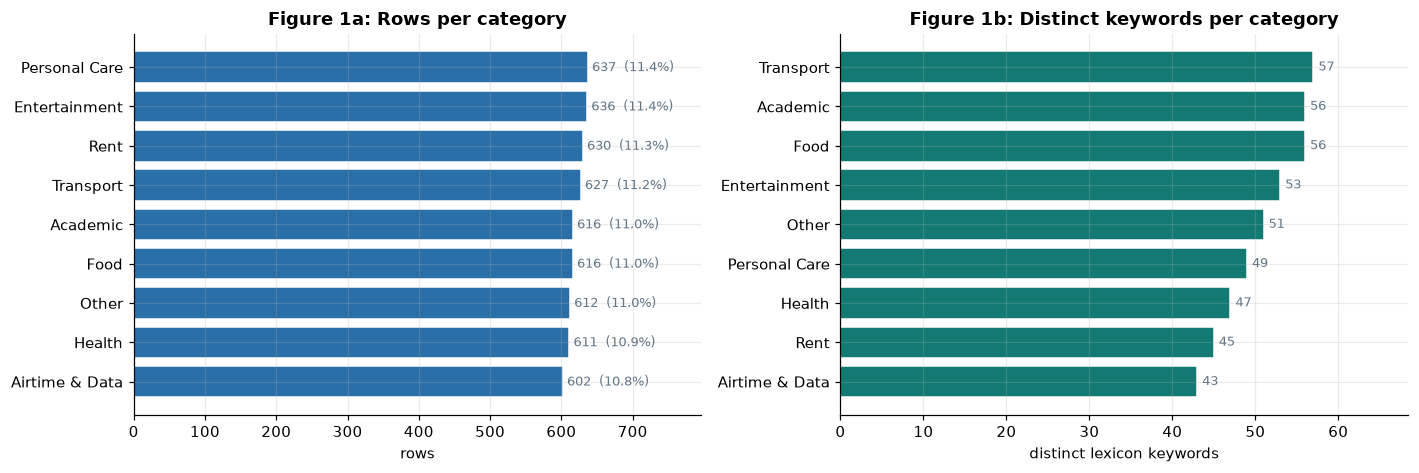

Class balance: max/min row ratio = 1.06  (1.00 would be perfectly even)
Keyword coverage: 43 (Airtime & Data) to 57 (Transport) keywords per category
Rows per keyword: 11.0 to 14.0


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))

counts = df.category.value_counts().sort_values()
axes[0].barh(counts.index, counts.values, color=BLUE, edgecolor="white")
axes[0].set_title("Figure 1a: Rows per category")
axes[0].set_xlabel("rows")
for i, v in enumerate(counts.values):
    axes[0].text(v + 6, i, f"{v}  ({v/len(df)*100:.1f}%)", va="center", fontsize=8.5, color=GREY)
axes[0].set_xlim(0, counts.max() * 1.25)

kws = kw_stats.keywords.sort_values()
axes[1].barh(kws.index, kws.values, color=TEAL, edgecolor="white")
axes[1].set_title("Figure 1b: Distinct keywords per category")
axes[1].set_xlabel("distinct lexicon keywords")
for i, v in enumerate(kws.values):
    axes[1].text(v + 0.6, i, str(v), va="center", fontsize=8.5, color=GREY)
axes[1].set_xlim(0, kws.max() * 1.2)

plt.tight_layout(); plt.show()

spread = counts.max() / counts.min()
print(f"Class balance: max/min row ratio = {spread:.2f}  (1.00 would be perfectly even)")
print(f"Keyword coverage: {kws.min()} ({kws.idxmin()}) to {kws.max()} ({kws.idxmax()}) keywords per category")
print(f"Rows per keyword: {kw_stats.rows_per_keyword.min():.1f} to {kw_stats.rows_per_keyword.max():.1f}")

Amount per category (KES):
                min  median    max
category                          
Airtime & Data   10   172.5   2987
Transport        50   411.0   2964
Food             50   503.0   4991
Other            50   567.0   9831
Personal Care   100   662.0   4979
Entertainment   100   748.5   4989
Health          100  1000.0   9912
Academic         20  1255.5  58090
Rent            307  3468.5  44911


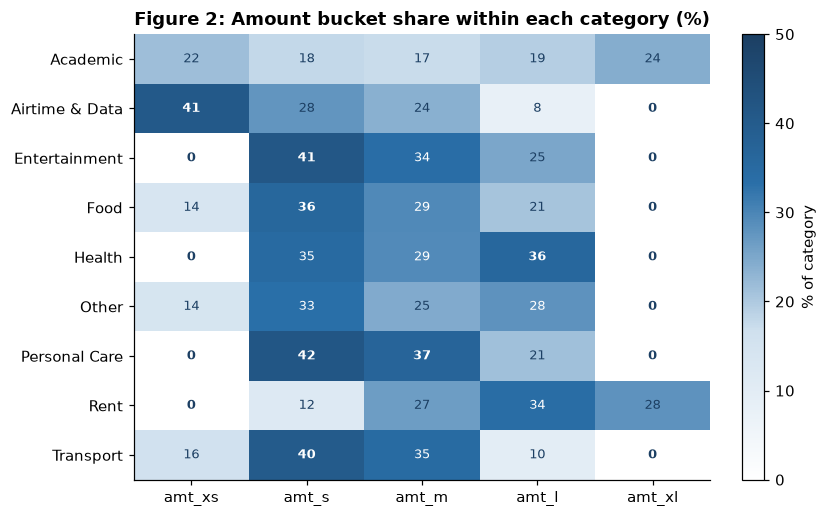

Categories that ever produce an amt_xl (>= KES 10,000) transaction:
  Academic (24.0%), Rent (27.9%)
Categories that never do: Airtime & Data, Entertainment, Food, Health, Other, Personal Care, Transport

Share of the amt_xs (< KES 100) rows held by each category:
  Airtime & Data 37.9%, Academic 20.6%, Transport 15.1%, Other 13.3%, Food 13.1%
Categories with no amt_xs rows at all: Entertainment, Health, Personal Care, Rent


In [12]:
# A printed summary replaces the boxplot: amounts come from fixed per-category ranges (Steps 3 and 6)
print("Amount per category (KES):")
print(df.groupby("category").amount.agg(["min", "median", "max"]).sort_values("median").to_string())

cats = sorted(df.category.unique())
pivot = (pd.crosstab(df.category, df.bucket, normalize="index")
           .reindex(columns=ORDER).fillna(0) * 100)
fig, ax = plt.subplots(figsize=(7.6, 4.8))
im = ax.imshow(pivot.values, cmap=HEAT, aspect="auto", vmin=0, vmax=50)
ax.set_xticks(range(len(ORDER))); ax.set_xticklabels(ORDER)
ax.set_yticks(range(len(pivot))); ax.set_yticklabels(pivot.index)
ax.set_title("Figure 2: Amount bucket share within each category (%)")
ax.grid(False)
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        v = pivot.values[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8.5,
                color="white" if v > 28 else NAVY,
                fontweight="bold" if v == 0 or v > 35 else "normal")
plt.colorbar(im, ax=ax, fraction=0.045, label="% of category")
plt.tight_layout(); plt.show()

print("Categories that ever produce an amt_xl (>= KES 10,000) transaction:")
xl = pivot["amt_xl"]
print("  " + ", ".join(f"{c} ({v:.1f}%)" for c, v in xl[xl > 0].items()) or "  none")
print("Categories that never do:", ", ".join(xl[xl == 0].index))
# Who makes the smallest payments: share of all amt_xs rows held by each category
xs = df.loc[df.bucket == "amt_xs", "category"].value_counts(normalize=True).mul(100).round(1)
print("\nShare of the amt_xs (< KES 100) rows held by each category:")
print("  " + ", ".join(f"{c} {v}%" for c, v in xs.items()))
print("Categories with no amt_xs rows at all:", ", ".join(c for c in cats if c not in xs.index))

In [13]:
from sklearn.feature_extraction.text import CountVectorizer
# Same settings as the model will use, so these counts are the real feature counts
vec_probe = CountVectorizer(**vectorizer_kwargs()); vec_probe.fit(df.doc)
uni_probe = CountVectorizer(lowercase=False, token_pattern=r"\S+"); uni_probe.fit(df.doc)

print(f"Description length: mean {df.n_tokens.mean():.2f} words, median {df.n_tokens.median():.0f}, "
      f"range {df.n_tokens.min()}-{df.n_tokens.max()}")
print(f"Most concentrated template word: {neutrality.max_category_share.max():.3f} of its rows in one "
      f"category, against {UNIFORM:.3f} for an even spread (table in Step 2)")
print(f"Vocabulary: {len(uni_probe.get_feature_names_out()):,} single words, "
      f"{len(vec_probe.get_feature_names_out()):,} features with word pairs included")
print(f"Rows: {len(df):,}  |  Features: {len(vec_probe.get_feature_names_out()):,}  "
      f"|  ratio = {len(df)/len(vec_probe.get_feature_names_out()):.2f} rows per feature")

Description length: mean 3.53 words, median 4, range 1-8
Most concentrated template word: 0.132 of its rows in one category, against 0.111 for an even spread (table in Step 2)
Vocabulary: 510 single words, 5,354 features with word pairs included
Rows: 5,587  |  Features: 5,354  |  ratio = 1.04 rows per feature


## Observations from the EDA

### Observation 1: the classes are balanced, but only because we made them so

Every category holds about 11% of the rows; the largest is only 1.06 times the smallest (Figure 1a).
That comes from `ROWS_PER_CATEGORY = 600` in the generator, not real spending. It makes accuracy a fair
metric, but the class priors will need updating on real data.

### Observation 2: the real imbalance is in the number of merchants

Keyword counts range from 43 (Airtime & Data) to 57 (Transport) (Figure 1b); the generator writes more
rows per keyword for thinner categories to level the row counts. A category with fewer keywords has a
narrower vocabulary, so it will struggle more with unseen merchants.

### Observation 3: the amount helps mainly at the extremes

Only Academic and Rent ever reach `amt_xl` (KES 10,000+). Airtime & Data holds the largest share of
`amt_xs` rows (37.9%), and Entertainment, Health, Personal Care and Rent never go below KES 100
(Figure 2). Most categories overlap in the middle, so the amount token helps mainly at the extremes, and
partly reflects our hand-set price ranges.

### Observation 4: descriptions are very short

Descriptions average 3.53 words (median 4, longest 8), mostly template words, so the signal is often the
merchant name alone. That suits Naive Bayes, which treats each word as separate evidence, but an unknown
merchant leaves little else to go on.

### Observation 5: the template words carry no category signal

No template word puts more than 0.132 of its rows in one category, against 0.111 for an even spread
(Step 2 table). So accuracy has to come from the merchant words and the amount token.

### Observation 6: there are as many features as rows

With word pairs there are 5,354 features for 5,587 rows, and most of the matrix is empty. This is where
models usually over-fit, another reason to prefer Naive Bayes; a single decision tree should over-fit
here, and in Part E it does.

---
# Part D: The base model
*CRISP-DM phases: modelling, then evaluation*

```
doc  →  CountVectorizer (single words + word pairs)  →  MultinomialNB  →  category
```

`CountVectorizer` turns each document into word counts, and Naive Bayes uses its default smoothing
(alpha = 1). The model is evaluated with **k-fold cross validation**: 5 stratified, shuffled folds with a
fixed seed, training on four and testing on the fifth in turn. Every model in this notebook uses the same
folds. The metric is **accuracy**, which is appropriate because the classes are near-balanced; random
guessing would score about 11%.

In [14]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict, cross_validate
from sklearn.metrics import confusion_matrix, precision_score, recall_score

X, y = df.doc, df.category
CLASSES = sorted(y.unique())
# One fixed set of 5 folds, reused by every model so the comparison is fair
SKF = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def make_pipeline(clf):
    # lowercase=False and token_pattern=r"\S+" (inside vectorizer_kwargs): the text is already cleaned,
    # and sklearn's default pattern would drop one-letter words that the app's TypeScript code keeps
    return Pipeline([("vec", CountVectorizer(**vectorizer_kwargs())), ("clf", clf)])

base_model = make_pipeline(MultinomialNB())
scores = cross_val_score(base_model, X, y, cv=SKF, scoring="accuracy")

print(f"{len(X):,} documents, {len(CLASSES)} classes")
print("Accuracy on each fold:", ", ".join(f"{s:.4f}" for s in scores))
print(f"Base model accuracy: {scores.mean():.4f} (+/- {scores.std():.4f})")
print(f"Random guessing:     {1/len(CLASSES):.4f}")

5,587 documents, 9 classes
Accuracy on each fold: 0.9776, 0.9741, 0.9696, 0.9731, 0.9785
Base model accuracy: 0.9746 (+/- 0.0032)
Random guessing:     0.1111


### A limitation of this score

Our training rows were generated from 457 merchant keywords, so several rows describe the same merchant.
A standard k-fold split can therefore place the same merchant in both the training and testing folds,
which means the score above is likely optimistic: the model may be recognising merchants it has already
seen rather than generalising to new ones. This is a form of overfitting to the training merchants.
Testing on real M-Pesa statements would give a more realistic figure.

## Precision, recall and the confusion matrix

Per-class **precision** (of the rows predicted as a category, how many really were) and **recall** (of
the rows in a category, how many were found) show where the errors are. Each row is predicted by the
fold model that did not train on it.

,precision,recall,rows
Academic,0.9983,0.9302,616
Airtime & Data,0.9625,0.9817,602
Entertainment,0.9517,0.9906,636
Food,0.9916,0.9627,616
Health,0.9711,0.9902,611
Other,0.9866,0.9657,612
Personal Care,0.9678,0.9922,637
Rent,0.9627,0.9841,630
Transport,0.9839,0.9729,627


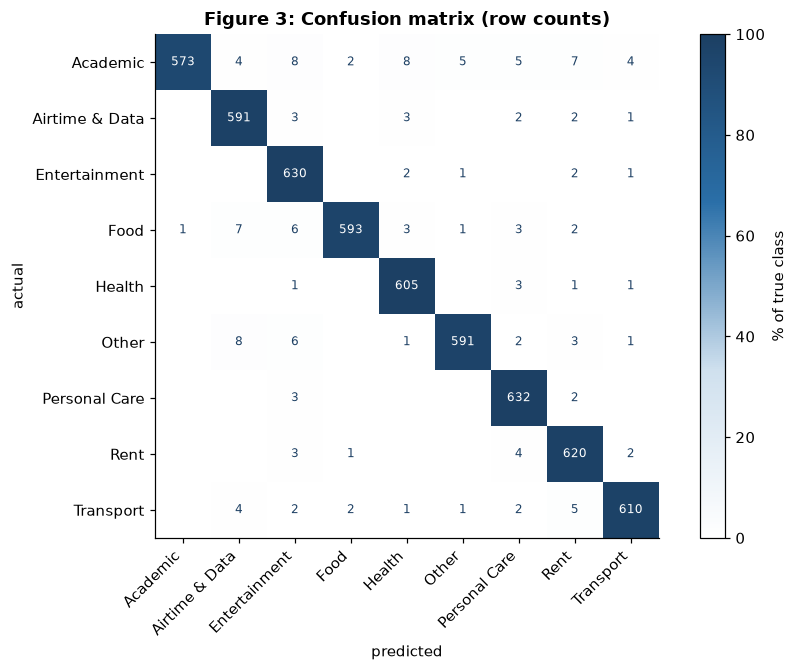

Most common mistakes (actual -> predicted: rows):
  Academic        -> Entertainment   8
  Academic        -> Health          8
  Other           -> Airtime & Data  8
  Academic        -> Rent            7
  Food            -> Airtime & Data  7

Rows misclassified: 142 of 5,587
Highest recall:    Personal Care (0.9922)
Lowest recall:     Academic (0.9302)
Lowest precision:  Entertainment (0.9517)
Accuracy of these out-of-fold predictions: 0.9746


In [15]:
# Each row is predicted by the fold model that was not trained on it
pred = cross_val_predict(base_model, X, y, cv=SKF)

per_class = pd.DataFrame({
    "precision": precision_score(y, pred, labels=CLASSES, average=None),
    "recall":    recall_score(y, pred, labels=CLASSES, average=None),
    "rows":      y.value_counts().reindex(CLASSES).values,
}, index=CLASSES).round(4)
display(per_class)
cm = confusion_matrix(y, pred, labels=CLASSES)

cmn = cm / cm.sum(axis=1, keepdims=True) * 100
fig, ax = plt.subplots(figsize=(8.4, 6.2))
im = ax.imshow(cmn, cmap=HEAT, vmin=0, vmax=100)
ax.set_xticks(range(len(CLASSES))); ax.set_xticklabels(CLASSES, rotation=45, ha="right")
ax.set_yticks(range(len(CLASSES))); ax.set_yticklabels(CLASSES)
ax.set_title("Figure 3: Confusion matrix (row counts)")
ax.set_xlabel("predicted"); ax.set_ylabel("actual"); ax.grid(False)
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        if cm[i, j]:
            ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=8,
                    color="white" if cmn[i, j] > 50 else NAVY)
plt.colorbar(im, ax=ax, fraction=0.045, label="% of true class")
plt.tight_layout(); plt.show()

# Off-diagonal cells are the mistakes; list the largest ones
mistakes = (pd.DataFrame(cm, index=CLASSES, columns=CLASSES)
              .where(~np.eye(len(CLASSES), dtype=bool)).stack().dropna().astype(int)
              .sort_values(ascending=False))
print("Most common mistakes (actual -> predicted: rows):")
for (actual, predicted), n in mistakes.head(5).items():
    print(f"  {actual:<15} -> {predicted:<15} {n}")
print(f"\nRows misclassified: {int(cm.sum() - np.trace(cm))} of {int(cm.sum()):,}")
print(f"Highest recall:    {per_class.recall.idxmax()} ({per_class.recall.max():.4f})")
print(f"Lowest recall:     {per_class.recall.idxmin()} ({per_class.recall.min():.4f})")
print(f"Lowest precision:  {per_class.precision.idxmin()} ({per_class.precision.min():.4f})")
print(f"Accuracy of these out-of-fold predictions: {(pred == y).mean():.4f}")

### Reading the base model's results

142 of the 5,587 rows are misclassified. Recall is highest for Personal Care (0.9922) and lowest for
Academic (0.9302), which loses rows mostly to Entertainment and Health (8 each) and Rent (7), likely
because its amounts span KES 20 to 60,000 and overlap every category (Observation 3). Entertainment has
the lowest precision (0.9517). As noted above, these scores are likely optimistic.

---
# Part E: Comparison models
*CRISP-DM phase: evaluation*

Five taught models go through the identical pipeline (same documents, `CountVectorizer`, folds and
metric), so any difference comes from the algorithm. The table also shows training-fold accuracy: much
higher training than test accuracy means **overfitting**, and low scores on both mean **underfitting**.

In [16]:
models = {
    "Multinomial Naive Bayes (base)": MultinomialNB(),
    "Logistic Regression":            LogisticRegression(max_iter=1000),
    "Decision Tree":                  DecisionTreeClassifier(random_state=42),
    "K-Nearest Neighbours":           KNeighborsClassifier(),
    "Random Forest":                  RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
    "Gradient Boosting":              GradientBoostingClassifier(random_state=42),
}

rows = []
for name, clf in models.items():
    # return_train_score=True also scores each model on its own training folds, to spot overfitting
    r = cross_validate(make_pipeline(clf), X, y, cv=SKF, scoring="accuracy",
                       return_train_score=True, n_jobs=-1)
    rows.append({"Model": name, "test_accuracy": r["test_score"].mean(), "std": r["test_score"].std(),
                 "train_accuracy": r["train_score"].mean()})
    print(f"  {name:<32} test {r['test_score'].mean():.4f}   train {r['train_score'].mean():.4f}")

comparison = (pd.DataFrame(rows)
                .assign(train_minus_test=lambda t: t.train_accuracy - t.test_accuracy)
                .sort_values("test_accuracy", ascending=False).round(4).reset_index(drop=True))
BASE_SCORE = comparison.loc[comparison.Model.str.contains("base"), "test_accuracy"].iloc[0]
print()
display(comparison)

  Multinomial Naive Bayes (base)   test 0.9746   train 0.9968


  Logistic Regression              test 0.9998   train 1.0000


  Decision Tree                    test 0.9042   train 1.0000


  K-Nearest Neighbours             test 0.2577   train 0.5495


  Random Forest                    test 0.9535   train 1.0000


  Gradient Boosting                test 0.9993   train 0.9996



,Model,test_accuracy,std,train_accuracy,train_minus_test
0,Logistic Regression,0.9998,0.0004,1.0000,0.0002
1,Gradient Boosting,0.9993,0.0009,0.9996,0.0003
2,Multinomial Naive Bayes (base),0.9746,0.0032,0.9968,0.0222
3,Random Forest,0.9535,0.0067,1.0000,0.0465
4,Decision Tree,0.9042,0.0109,1.0000,0.0958
5,K-Nearest Neighbours,0.2577,0.0163,0.5495,0.2918


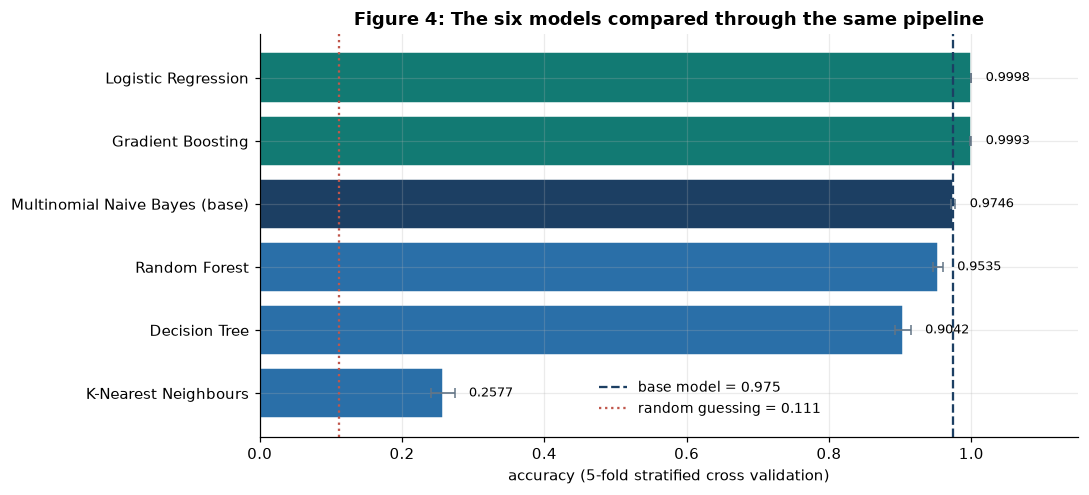

Best performer : Logistic Regression  (0.9998)
Base model     : 0.9746
Difference     : +0.0252 accuracy


In [17]:
fig, ax = plt.subplots(figsize=(10, 4.6))
c = comparison.sort_values("test_accuracy")
colours = [NAVY if "base" in m else TEAL if s > BASE_SCORE else BLUE
           for m, s in zip(c.Model, c.test_accuracy)]
bars = ax.barh(c.Model, c.test_accuracy, xerr=c["std"], color=colours, edgecolor="white",
               error_kw=dict(ecolor=GREY, lw=1.1, capsize=3))
ax.axvline(BASE_SCORE, color=NAVY, linestyle="--", linewidth=1.5,
           label=f"base model = {BASE_SCORE:.3f}")
ax.axvline(1/len(CLASSES), color=RED, linestyle=":", linewidth=1.5,
           label=f"random guessing = {1/len(CLASSES):.3f}")
ax.set_xlabel("accuracy (5-fold stratified cross validation)")
ax.set_title("Figure 4: The six models compared through the same pipeline")
# Legend sits in the empty space beside the shortest bar, clear of the base-model line
ax.legend(frameon=False, fontsize=9, loc="lower left", bbox_to_anchor=(0.4, 0.02))
for b, v, sd in zip(bars, c.test_accuracy, c["std"]):
    ax.text(v + sd + 0.02, b.get_y() + b.get_height()/2, f"{v:.4f}", va="center", fontsize=8.5)
ax.set_xlim(0, 1.15)
plt.tight_layout(); plt.show()

best = comparison.iloc[0]
print(f"Best performer : {best.Model}  ({best.test_accuracy:.4f})")
print(f"Base model     : {BASE_SCORE:.4f}")
print(f"Difference     : {best.test_accuracy - BASE_SCORE:+.4f} accuracy")

### Why K-Nearest Neighbours does so badly

KNN labels a row by its 5 closest training rows, and with word counts "closest" means "shares the most
words". The check below shows what each row has in common with its nearest neighbours.

In [18]:
from sklearn.neighbors import NearestNeighbors

# Distances are measured on the same word-count vectors the KNN model uses
count_matrix = CountVectorizer(**vectorizer_kwargs()).fit_transform(X)
_, idx = NearestNeighbors(n_neighbors=6).fit(count_matrix).kneighbors(count_matrix)
neighbours = idx[:, 1:]   # column 0 is the row itself

# A row's template is its description with the merchant keyword blanked out
template = np.asarray([d.replace(k, "{kw}") for d, k in zip(df.description, df.keyword)], dtype=object)
for label, values in [("same template", template),
                      ("same merchant keyword", df.keyword.to_numpy(dtype=object)),
                      ("same category", df.category.to_numpy(dtype=object))]:
    print(f"Neighbours with the {label:<22} {(values[neighbours] == values[:, None]).mean():.1%}")

Neighbours with the same template          92.3%
Neighbours with the same merchant keyword  7.2%
Neighbours with the same category          23.8%


## What the comparison shows

- Logistic Regression (0.9998) and Gradient Boosting (0.9993) beat the Naive Bayes base model (0.9746).
- The Decision Tree overfits, as Observation 6 predicted: 100% on training folds but 0.9042 on test
  folds. Random Forest halves that gap (0.9535) but still trails Naive Bayes.
- K-Nearest Neighbours underfits (0.5495 train, 0.2577 test): 92.3% of each row's neighbours share its
  template but only 7.2% share its merchant.
- Naive Bayes shows only a small train/test gap (0.9968 against 0.9746).

The near-100% scores at the top are probably mostly the repeated-merchant effect from Part D.

## Regularisation

The notes describe regularisation as a penalty that keeps a model's weights small, simplifying it to
reduce overfitting. Lasso (L1) and ridge (L2) are the standard penalties, and scikit-learn's Logistic
Regression uses ridge by default; a smaller `C` means stronger regularisation. Naive Bayes has no such
penalty, so the sweep uses Logistic Regression.

In [19]:
sweep = []
for C in [0.01, 0.1, 1.0, 10.0, 100.0]:
    # Smaller C = bigger penalty on the weights = stronger regularisation
    r = cross_validate(make_pipeline(LogisticRegression(max_iter=1000, C=C)), X, y, cv=SKF,
                       scoring="accuracy", return_train_score=True, n_jobs=-1)
    sweep.append({"C": C, "regularisation": "strong" if C < 1 else "weak" if C > 1 else "default",
                  "train_accuracy": r["train_score"].mean(), "test_accuracy": r["test_score"].mean()})
sweep_df = pd.DataFrame(sweep).round(4)
display(sweep_df)

strongest, best_row = sweep_df.iloc[0], sweep_df.loc[sweep_df.test_accuracy.idxmax()]
print(f"Strongest regularisation (C = {strongest.C}): train {strongest.train_accuracy:.4f}, "
      f"test {strongest.test_accuracy:.4f}")
print(f"Best test accuracy: {best_row.test_accuracy:.4f} at C = {best_row.C}")

,C,regularisation,train_accuracy,test_accuracy
0,0.01,strong,0.5855,0.5158
1,0.10,strong,0.9858,0.9465
2,1.00,default,1.0000,0.9998
3,10.00,weak,1.0000,1.0000
4,100.00,weak,1.0000,1.0000


Strongest regularisation (C = 0.01): train 0.5855, test 0.5158
Best test accuracy: 1.0000 at C = 10.0


Strong regularisation (C = 0.01) underfits (0.5855 train, 0.5158 test). Weaker regularisation helps, and
from C = 10 both scores reach 1.0000. Less regularisation winning is another sign of the repeated-merchant
effect: when the test folds hold the same merchants, memorising them is rewarded.

---
# Part F: Conclusions
*CRISP-DM phases: evaluation and deployment*

The base model, `CountVectorizer` with Multinomial Naive Bayes, scores 0.9746 accuracy in 5-fold
stratified cross validation, against about 0.11 for random guessing. Logistic Regression (0.9998) and
Gradient Boosting (0.9993) score higher, the tree models overfit and KNN underfits. These scores are likely
optimistic: the 5,587 rows come from only 457 merchant keywords, so the same merchant usually sits in both
training and test folds and the models are partly tested on merchants they have already seen, a form of
overfitting to the training merchants. Real M-Pesa statements would give a more realistic figure, and
until the comparison is repeated on them Naive Bayes stays as the shipped model.

For deployment, `scripts/train.py` builds the shipped model exactly as Part D does (its accuracy in
`out/metrics.json` matches the 0.9746 above), and `scripts/export.py` writes it to `out/model.json` for
the app's TypeScript server.

Next steps:

1. Label a few hundred real statement rows (via `extract.py`) as `data/test_real.csv`.
2. Re-run the comparison on that real test set.
3. Add merchants to `lexicon.json`, especially in thinner categories (Observation 2).
4. Send low-confidence predictions to the user to confirm.

To reproduce, from the repository root:

```bash
pip install -r requirements.txt
python scripts/generate.py          # lexicon.json -> data/train.csv
jupyter notebook notebooks/NaiveBayes_Base.ipynb
```